# Week 7: Text and Multimodal AI

| | |
|---|---|
| **Student name** | **Zubeda Raheem** |
| **Subject** | **Introduction to Applied AI** |
| **Project** | **Malaria diagnosis: blood-smear image + clinical text case review** (continues my Week 6 blood-cell classifier, `Parasitized` vs `Uninfected`) |

**Order of this notebook:** Part 1 TF-IDF, Part 2 text classification, Part 3 NER, Part 4 regex, Part 5 CER and OCR, Part 6 image + text case record, then **Check Your Understanding**. Each part ends with a **Write it** cell that explains the measured output.


In [1]:
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

nlp = spacy.load('en_core_web_sm')     # preinstalled on Kaggle
print('spaCy', spacy.__version__)

spaCy 3.8.16


In [2]:
docs = ['win free cash now', 'call me now', 'free call now']
vec = TfidfVectorizer()                # smooth idf + L2 normalization
X = vec.fit_transform(docs)
print(pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out(),
                   index=['d1', 'd2', 'd3']).round(3))

# Reproduce d1 by hand: idf = ln((1 + N) / (1 + df)) + 1
N = 3
idf = {'win': np.log(4 / 2) + 1, 'free': np.log(4 / 3) + 1,
       'cash': np.log(4 / 2) + 1, 'now': np.log(4 / 4) + 1}
v = np.array(list(idf.values()))       # tf = 1 for each word in d1
print({w: round(x, 3) for w, x in zip(idf, v / np.linalg.norm(v))})

     call   cash   free    me    now    win
d1  0.000  0.584  0.445  0.00  0.345  0.584
d2  0.548  0.000  0.000  0.72  0.425  0.000
d3  0.620  0.000  0.620  0.00  0.481  0.000
{'win': np.float64(0.584), 'free': np.float64(0.445), 'cash': np.float64(0.584), 'now': np.float64(0.345)}


## **Write it: Part 1, TF-IDF by Hand**

**What I checked.** Before trusting `TfidfVectorizer`, I rebuilt one row of its output myself. **TF** counts how often a word appears in one document. **IDF** measures how **rare** the word is across all documents. The score is **TF x IDF**, and each document vector is then scaled to **length 1** (L2 normalisation) so long and short messages can be compared fairly.

**1. IDF arithmetic** (smooth version, N = 3 documents): `idf = ln[(1 + N) / (1 + df)] + 1`

| Word | Appears in | df | Calculation | IDF |
|---|---|---|---|---|
| **free** | d1, d3 | 2 | ln(4/3) + 1 = 0.288 + 1 | **1.288** |
| **now** | d1, d2, d3 | 3 | ln(4/4) + 1 = 0 + 1 | **1.000** |
| **win**, **cash** | d1 only | 1 | ln(4/2) + 1 = 0.693 + 1 | **1.693** |

**2. Why "now" gets the lowest weight.** "now" is in **every** document, so it cannot tell one message from another. The log term becomes ln(1) = **0**, and only the +1 smoothing is left, which is the **minimum possible IDF**. In d1 this is visible: **win** and **cash** score **0.584**, **free** scores **0.445**, and **now** only **0.345**.

**3. Reproducing d1 by hand.** With tf = 1 for each word, the raw vector is [1.693, 1.288, 1.693, 1.000]. Its length is sqrt(1.693² + 1.288² + 1.693² + 1.000²) = sqrt(8.392) = **2.897**. Dividing gives **win 0.584, free 0.445, cash 0.584, now 0.345**. My dictionary printout and the scikit-learn table matched on **all four numbers**, so I understand what the library does internally.

**4. Cosine similarity of d2 and d3.** Both vectors have length 1, so cosine similarity is just the **dot product**, and only shared words contribute:
- **call:** 0.548 x 0.620 = **0.340**
- **now:** 0.425 x 0.481 = **0.204**
- me, free, cash, win: one of the two vectors is 0, so they add **nothing**

**cos(d2, d3) = 0.340 + 0.204 = 0.544.**

**5. What it means.** The two messages look similar mostly because of **call**. The shared word "now" adds only 0.204 because its IDF is the lowest possible. So TF-IDF rewards shared **informative** words more than shared **common** words, which is why it works well for spam filtering.


In [3]:
import os
for root, dirs, files in os.walk('/kaggle/input'):
    if 'spam' in root.lower() or 'sms' in root.lower():
        for f in files:
            print(os.path.join(root, f))
    if root.count('/') >= 5:      # do not go deeper
        dirs[:] = []

/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv


In [4]:
path = '/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv'
sms = pd.read_csv(path, encoding='latin-1')[['v1', 'v2']]
sms.columns = ['label', 'text']
sms['y'] = (sms['label'] == 'spam').astype(int)
print(sms['label'].value_counts().to_string())
print(f"Spam share: {sms['y'].mean():.3f}   "
      f"'always ham' accuracy: {1 - sms['y'].mean():.3f}")

label
ham     4825
spam     747
Spam share: 0.134   'always ham' accuracy: 0.866


              precision    recall  f1-score   support

         ham      0.990     0.997     0.993       966
        spam      0.979     0.933     0.955       149

    accuracy                          0.988      1115
   macro avg      0.984     0.965     0.974      1115
weighted avg      0.988     0.988     0.988      1115



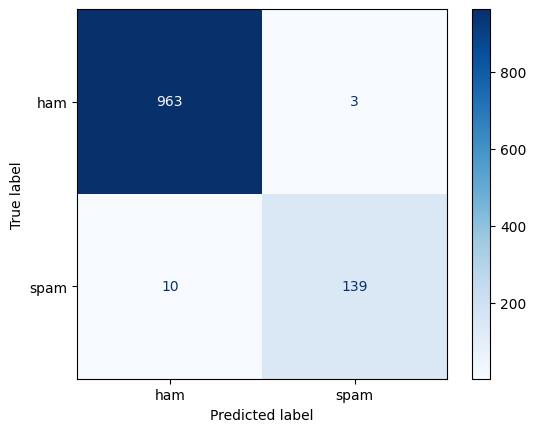

In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(
    sms['text'], sms['y'], test_size=0.2, random_state=42,
    stratify=sms['y'])

word_clf = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                              sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
word_clf.fit(X_tr, y_tr)
pred = word_clf.predict(X_te)
print(classification_report(y_te, pred, target_names=['ham', 'spam'],
                            digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred),
                       display_labels=['ham', 'spam']).plot(cmap='Blues')
plt.show()

In [6]:
tfidf_step = word_clf.named_steps['tfidf']
w = word_clf.named_steps['model'].coef_[0]
terms = tfidf_step.get_feature_names_out()
order = np.argsort(w)
print('Most spam-like :', list(terms[order[-12:]][::-1]))
print('Most ham-like  :', list(terms[order[:12]]))

Most spam-like : ['call', 'txt', 'free', 'text', 'reply', 'uk', 'to', 'www', 'mobile', 'claim', 'stop', 'your']
Most ham-like  : ['my', 'me', 'ok', 'that', 'it', 'but', 'll', 'gt', 'lt', 'can', 'what', 'da']


In [7]:
char_clf = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5),
                              min_df=2, sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
char_clf.fit(X_tr, y_tr)

for name, clf in [('word 1-2 grams', word_clf), ('char 2-5 grams', char_clf)]:
    p = clf.predict(X_te)
    print(f'{name:15s} macro-F1 {f1_score(y_te, p, average="macro"):.3f}   '
          f'features {len(clf.named_steps["tfidf"].vocabulary_):,}')

print()
for name, clf in [('word', word_clf), ('char', char_clf)]:
    print(name)
    print(classification_report(y_te, clf.predict(X_te),
                                target_names=['ham', 'spam'], digits=3))

# Robustness to spelling tricks (the lab's two examples)
tricky = ['W1N a FR33 pr1ze!! txt CLAIM now', 'kal milte hain, 5 baje']
print('word:', dict(zip(tricky, word_clf.predict_proba(tricky)[:, 1].round(2))))
print('char:', dict(zip(tricky, char_clf.predict_proba(tricky)[:, 1].round(2))))

word 1-2 grams  macro-F1 0.974   features 12,128
char 2-5 grams  macro-F1 0.982   features 36,449

word
              precision    recall  f1-score   support

         ham      0.990     0.997     0.993       966
        spam      0.979     0.933     0.955       149

    accuracy                          0.988      1115
   macro avg      0.984     0.965     0.974      1115
weighted avg      0.988     0.988     0.988      1115

char
              precision    recall  f1-score   support

         ham      0.993     0.998     0.995       966
        spam      0.986     0.953     0.969       149

    accuracy                          0.992      1115
   macro avg      0.989     0.975     0.982      1115
weighted avg      0.992     0.992     0.992      1115

word: {'W1N a FR33 pr1ze!! txt CLAIM now': np.float64(0.99), 'kal milte hain, 5 baje': np.float64(0.19)}
char: {'W1N a FR33 pr1ze!! txt CLAIM now': np.float64(0.85), 'kal milte hain, 5 baje': np.float64(0.12)}


In [8]:
mine = ['Bhai call kar do, free ho to mobile pe load bhej dena, urgent hai',
        'EasyPaisa acc0unt b1ocked! Cl1ck www.easypaisa-verify.pk 2 cla1m Rs5000 b0nus 2day']
print('word:', dict(zip(mine, word_clf.predict_proba(mine)[:, 1].round(2))))
print('char:', dict(zip(mine, char_clf.predict_proba(mine)[:, 1].round(2))))

word: {'Bhai call kar do, free ho to mobile pe load bhej dena, urgent hai': np.float64(0.93), 'EasyPaisa acc0unt b1ocked! Cl1ck www.easypaisa-verify.pk 2 cla1m Rs5000 b0nus 2day': np.float64(0.66)}
char: {'Bhai call kar do, free ho to mobile pe load bhej dena, urgent hai': np.float64(0.64), 'EasyPaisa acc0unt b1ocked! Cl1ck www.easypaisa-verify.pk 2 cla1m Rs5000 b0nus 2day': np.float64(0.6)}


In [9]:
p_te = word_clf.predict_proba(X_te)[:, 1]
err = pd.DataFrame({'text': X_te, 'true': y_te, 'p_spam': p_te})
err = err[(err.p_spam >= 0.5) != (err.true == 1)]
pd.set_option('display.max_colwidth', 90)
print(err.sort_values('p_spam').to_string())

                                                                                                                                                                                       text  true    p_spam
750                                                                                  Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?     1  0.087598
2246  Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafone no, if you respond you get further prem rate msg/subscription. Other nos used also. Beware!     1  0.144048
3979                                                                                                                                                                     ringtoneking 84484     1  0.192426
1429                                                                                                                For sale - arsenal dartboard. Good condition but no doubles or trebl

## **Write it: Part 2, Text Classification (Word vs Character n-grams)**

**1. Data and baseline.** SMS Spam Collection: **5,572** messages, **4,825 ham** and **747 spam** (**13.4%** spam). A model that always says "ham" is already **86.6%** accurate, so plain accuracy is a **weak** measure here. I therefore compare **macro-F1**, which gives the rare spam class the same weight as ham. The split is **80/20, stratified, random_state = 42**, so the test set has **1,115** messages (**966 ham, 149 spam**).

**2. Metrics**

| Metric (test set) | Word 1-2 grams | Char 2-5 grams |
|---|---|---|
| Features learned | 12,128 | 36,449 |
| **Macro-F1** | 0.974 | **0.982** |
| Spam precision | 0.979 | **0.986** |
| Spam recall | 0.933 | **0.953** |
| Accuracy | 0.988 | **0.992** |

**3. Which model is better?** The **character model**, on every metric. In message counts the word model caught **139 of 149** spam messages with **3** false alarms, and the character model caught about **142** with about **2** false alarms. The margin is small (**0.008** macro-F1) and comes from **one** split of 1,115 messages, so it is a **consistent edge, not proof**. The cost is **about 3 times as many features**.

**4. What the word model learned** (largest coefficients)
- **Spam-like:** call, txt, free, text, reply, uk, to, www, mobile, claim, stop, your
- **Ham-like:** my, me, ok, that, it, but, ll, gt, lt, can, what, da
- **Sensible features:** **txt, claim, free, www, stop, reply, mobile** are how promotions ask for action. The ham side is personal chat words (**my, me, ok**).
- **Shortcuts, not understanding:** **uk** reflects where the data was collected. **to** and **your** are common words that happen to be frequent in spam here. **gt** and **lt** are leftovers of the HTML codes `&gt;` and `&lt;` in friends' texts. **ll** is what remains of "I'll", and **da** is chat slang. The model partly learns the **style of the dataset**, not the nature of spam.

**5. Tricky messages** (spam probability)

| Message | Word | Char |
|---|---|---|
| Lab: `W1N a FR33 pr1ze!! txt CLAIM now` (spam) | 0.99 | 0.85 |
| Lab: `kal milte hain, 5 baje` (ham) | 0.19 | 0.12 |
| **Mine:** `Bhai call kar do, free ho to mobile pe load bhej dena, urgent hai` (genuine ham, Roman Urdu) | **0.93** | **0.64** |
| **Mine:** `EasyPaisa acc0unt b1ocked! Cl1ck www.easypaisa-verify.pk 2 cla1m Rs5000 b0nus 2day` (disguised spam) | 0.66 | 0.60 |

- My **ordinary Roman Urdu request** was flagged as spam by **both** models, because it contains the English alarm words **call, free, mobile, urgent**. The Urdu words around them are unseen and add nothing. The models respond to **vocabulary, not meaning**. The character model is calmer (0.64 vs 0.93) but still crosses 0.5.
- My **disguised spam** was caught, but only with **weak confidence** (0.66 and 0.60), and the character model did **not** beat the word model. Character n-grams helped on the lab's `W1N / FR33` example, but my message mixes scattered digits with a fake local brand that neither model has seen.

**6. Error analysis** (word model, **13 mistakes**: 10 missed spam and 3 false alarms). The labels below are **my judgment** from the content; I cannot see how the original annotators decided.

| Message (shortened) | True | P(spam) | My verdict | Reason |
|---|---|---|---|---|
| "old ladies with tattoos in 40 years" | spam | 0.09 | **Label error** | Pure joke, no spam signal |
| "Hi ya babe... scammers getting smart" | spam | 0.14 | **Ambiguous** | A warning about spam written like the spam it describes |
| "ringtoneking 84484" | spam | 0.19 | **Model error** | Only two tokens, too little evidence |
| "arsenal dartboard for sale" | spam | 0.21 | **Label error** | Reads like an ordinary classified ad |
| "ROMCAPspam... breath of sunshine" | spam | 0.25 | **Model error** | Horoscope subscription; the clue is one rare token, the rest sounds friendly |
| "Sorry I missed your call... 07090201529" | spam | 0.28 | **Model error** | The only clue is the premium **070** number prefix, which word tokens ignore |
| "Police station toilet stolen" | spam | 0.31 | **Ambiguous** | Joke-of-the-day subscription, no spam words |
| "FreeMsg Hey there darling..." | spam | 0.41 | **Model error** | Obvious spam just below the 0.5 threshold |
| "Download as many ringtones... Txt Sir to 80082" | spam | 0.42 | **Model error** | Obvious spam just below the threshold |
| "Can U get 2 phone NOW... Call me NOW on 09096..." | spam | 0.46 | **Model error** | Chatty tone pulled it down; premium-rate number ignored |
| "We have sent JD for Customer Service... ur mail id" | ham | 0.62 | **Ambiguous** | Could be a real recruiter or a job-ad scam |
| "Ok... Ur typical reply..." | ham | 0.64 | **Model error** | Plain chat; "ur" pushed it the wrong way |
| "Waiting for your call." | ham | 0.85 | **Model error** | "call" and "your" are two of its top spam shortcuts |

**Count: 8 model errors, 2 label errors, 3 ambiguous.** At least **5 of 13** are not really the model's fault, so the **ceiling of this dataset is below 100%**. The model errors cluster in two groups: three spam misses sit between **0.41 and 0.46**, just under the line (a lower threshold might recover them, but it must be tested on **all** messages, since I only inspected the errors); and several depend on **phone-number prefixes** (070, 090) that word tokens cannot capture. A **regex feature** (Part 4) could supply exactly that.

**7. Limitation of a random split.** Test messages come from the **same collection** as the training messages, so they look like what the model has seen. Real future messages change (new scams, new wording, **Roman Urdu**), as my own two messages showed. The test score is therefore **optimistic**, and the data is **English and UK-heavy**.

**Conclusion.** The **character model** is better here (macro-F1 **0.982 vs 0.974**, spam recall **0.953 vs 0.933**), but both models rely on **vocabulary shortcuts** and both failed on my Roman Urdu message.


In [10]:
sentences = [
    'Dr. Maham Fatima at PIMS Islamabad reviewed it on 12 September 2026.',
    'The invoice from Engro Fertilizers for PKR 45,000 is due on 30/09/2026.',
    'Farmer Zaryab Ali from Multan reported leaf rust in his wheat crop.',
    'Call Jazz support at 0300-1234567 or email help@jazz.com.pk.',
    'Meezan Bank approved a loan of Rs. 250,000 for Alisha Noor.',
    'The consignment left Karachi Port on Monday for Lahore.']
for s in sentences:
    doc = nlp(s)
    print([(e.text, e.label_) for e in doc.ents])

[('Maham Fatima', 'PERSON'), ('PIMS Islamabad', 'LOC'), ('12 September 2026', 'DATE')]
[('Engro Fertilizers', 'PERSON'), ('30/09/2026', 'GPE')]
[('Farmer Zaryab Ali', 'PERSON'), ('Multan', 'GPE')]
[('0300-1234567', 'DATE')]
[('Meezan Bank', 'ORG'), ('250,000', 'CARDINAL'), ('Alisha Noor', 'PERSON')]
[('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')]


In [11]:
gold = [
    {('Maham Fatima', 'PERSON'), ('PIMS', 'ORG'), ('Islamabad', 'GPE'),
     ('12 September 2026', 'DATE')},
    {('Engro Fertilizers', 'ORG'), ('PKR 45,000', 'MONEY'),
     ('30/09/2026', 'DATE')},
    {('Zaryab Ali', 'PERSON'), ('Multan', 'GPE')},
    {('Jazz', 'ORG')},
    {('Meezan Bank', 'ORG'), ('Rs. 250,000', 'MONEY'),
     ('Alisha Noor', 'PERSON')},
    {('Karachi Port', 'FAC'), ('Monday', 'DATE'), ('Lahore', 'GPE')}]

def ner_scores(nlp_model):
    tp = fp = fn = 0
    for s, g in zip(sentences, gold):
        pred = {(e.text, e.label_) for e in nlp_model(s).ents}
        tp += len(pred & g)
        fp += len(pred - g)
        fn += len(g - pred)
    p, r = tp / (tp + fp), tp / (tp + fn)
    return {'precision': round(p, 3), 'recall': round(r, 3),
            'f1': round(2 * p * r / (p + r), 3)}

print('spaCy out of the box:', ner_scores(nlp))

spaCy out of the box: {'precision': 0.571, 'recall': 0.5, 'f1': 0.533}


In [12]:
nlp_base = spacy.load('en_core_web_sm')     # untouched copy for "before" scores

ruler = nlp.add_pipe('entity_ruler', before='ner')
ruler.add_patterns([
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                   {'IS_PUNCT': True, 'OP': '?'},
                                   {'LIKE_NUM': True}]},
    {'label': 'ORG', 'pattern': 'Engro Fertilizers'},
    {'label': 'ORG', 'pattern': 'Meezan Bank'},
    {'label': 'ORG', 'pattern': 'PIMS'},
    {'label': 'ORG', 'pattern': 'Jazz'},
    {'label': 'FAC', 'pattern': 'Karachi Port'},
    {'label': 'DATE',
     'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
])
print('spaCy + entity ruler:', ner_scores(nlp))

spaCy + entity ruler: {'precision': 0.875, 'recall': 0.875, 'f1': 0.875}


In [13]:
import spacy
nlp_base = spacy.load('en_core_web_sm')

dom_sents = [
    # --- rule-writing set (1-5) ---
    'Dr. Maham Fatima at PIMS Islamabad reported 12 parasitized smears on 05/10/2026.',
    'Chughtai Lab charged PKR 1,500 for a blood smear test on 14/10/2026.',
    'Zaryab Ali from Rawalpindi was treated for malaria at Holy Family Hospital on Friday.',
    'Alisha Noor paid Rs. 800 at Shifa International in Islamabad.',
    'Call the Aga Khan Laboratory at 0321-5551234 about the slides due on 20 November 2026.',
    # --- held-out test set (6-10) ---
    'Hira Malik from Lahore visited Mayo Hospital on Tuesday with fever.',
    'The Punjab Health Department bought test kits for PKR 250,000 on 03/11/2026.',
    'Sana Iqbal donated Rs. 15,000 to Edhi Foundation in Karachi.',
    'World Health Organization opened a malaria clinic in Peshawar on 25 December 2026.',
    'Zainab Khan reported 40 infected cells at Aga Khan University Hospital on Sunday.']

dom_gold = [
    {('Maham Fatima', 'PERSON'), ('PIMS', 'ORG'), ('Islamabad', 'GPE'),
     ('05/10/2026', 'DATE')},
    {('Chughtai Lab', 'ORG'), ('PKR 1,500', 'MONEY'), ('14/10/2026', 'DATE')},
    {('Zaryab Ali', 'PERSON'), ('Rawalpindi', 'GPE'),
     ('Holy Family Hospital', 'ORG'), ('Friday', 'DATE')},
    {('Alisha Noor', 'PERSON'), ('Rs. 800', 'MONEY'),
     ('Shifa International', 'ORG'), ('Islamabad', 'GPE')},
    {('Aga Khan Laboratory', 'ORG'), ('20 November 2026', 'DATE')},
    # held-out
    {('Hira Malik', 'PERSON'), ('Lahore', 'GPE'), ('Mayo Hospital', 'ORG'),
     ('Tuesday', 'DATE')},
    {('Punjab Health Department', 'ORG'), ('PKR 250,000', 'MONEY'),
     ('03/11/2026', 'DATE')},
    {('Sana Iqbal', 'PERSON'), ('Rs. 15,000', 'MONEY'),
     ('Edhi Foundation', 'ORG'), ('Karachi', 'GPE')},
    {('World Health Organization', 'ORG'), ('Peshawar', 'GPE'),
     ('25 December 2026', 'DATE')},
    {('Zainab Khan', 'PERSON'), ('40', 'CARDINAL'),
     ('Aga Khan University Hospital', 'ORG'), ('Sunday', 'DATE')}]

def score_on(model, sents, gold_sets):
    tp = fp = fn = 0
    for s, g in zip(sents, gold_sets):
        pred = {(e.text, e.label_) for e in model(s).ents}
        tp += len(pred & g); fp += len(pred - g); fn += len(g - pred)
    p, r = tp / (tp + fp), tp / (tp + fn)
    return {'precision': round(p, 3), 'recall': round(r, 3),
            'f1': round(2 * p * r / (p + r), 3)}

print('BEFORE rules, sentences 1-5 :', score_on(nlp_base, dom_sents[:5], dom_gold[:5]))
print('BEFORE rules, held-out 6-10 :', score_on(nlp_base, dom_sents[5:], dom_gold[5:]))
print()
for s in dom_sents[:5]:        # study ONLY the first five to design rules
    print([(e.text, e.label_) for e in nlp_base(s).ents])

BEFORE rules, sentences 1-5 : {'precision': 0.533, 'recall': 0.471, 'f1': 0.5}
BEFORE rules, held-out 6-10 : {'precision': 0.778, 'recall': 0.778, 'f1': 0.778}

[('Maham Fatima', 'PERSON'), ('PIMS Islamabad', 'ORG'), ('12', 'CARDINAL')]
[('Chughtai Lab', 'PERSON'), ('PKR 1,500', 'PRODUCT'), ('14/10/2026', 'DATE')]
[('Zaryab Ali', 'PERSON'), ('Rawalpindi', 'PERSON'), ('Holy Family Hospital', 'ORG'), ('Friday', 'DATE')]
[('Alisha Noor', 'PERSON'), ('Shifa International', 'FAC'), ('Islamabad', 'GPE')]
[('the Aga Khan Laboratory', 'PERSON'), ('20 November 2026', 'DATE')]


In [14]:
dom_gold[0].add(('12', 'CARDINAL'))      # consistent annotation fix

nlp_dom = spacy.load('en_core_web_sm')
ruler = nlp_dom.add_pipe('entity_ruler', before='ner')
ruler.add_patterns([
    # money formats
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                   {'IS_PUNCT': True, 'OP': '?'},
                                   {'LIKE_NUM': True}]},
    # numeric dates like 05/10/2026
    {'label': 'DATE',
     'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
    # mobile numbers, claimed so they are not read as dates (handled by regex in Part 4)
    {'label': 'PHONE',
     'pattern': [{'TEXT': {'REGEX': r'^0\d{3}-\d{7}$'}}]},
    # names seen in sentences 1-5
    {'label': 'ORG', 'pattern': 'PIMS'},
    {'label': 'GPE', 'pattern': 'Islamabad'},
    {'label': 'GPE', 'pattern': 'Rawalpindi'},
    # shape rule: capitalised words ending in a lab/hospital word
    {'label': 'ORG',
     'pattern': [{'IS_TITLE': True, 'OP': '+'},
                 {'LOWER': {'IN': ['lab', 'laboratory', 'hospital',
                                   'international']}}]},
])

def score_dom(model, sents, gold_sets, ignore=('PHONE',)):
    tp = fp = fn = 0
    for s, g in zip(sents, gold_sets):
        pred = {(e.text, e.label_) for e in model(s).ents if e.label_ not in ignore}
        tp += len(pred & g); fp += len(pred - g); fn += len(g - pred)
    p, r = tp / (tp + fp), tp / (tp + fn)
    return {'precision': round(p, 3), 'recall': round(r, 3),
            'f1': round(2 * p * r / (p + r), 3)}

print('BEFORE, sentences 1-5 :', score_dom(nlp_base, dom_sents[:5], dom_gold[:5]))
print('BEFORE, held-out 6-10 :', score_dom(nlp_base, dom_sents[5:], dom_gold[5:]))
print('AFTER , sentences 1-5 :', score_dom(nlp_dom, dom_sents[:5], dom_gold[:5]))
print('AFTER , held-out 6-10 :', score_dom(nlp_dom, dom_sents[5:], dom_gold[5:]))
print()
for s in dom_sents[5:]:
    print([(e.text, e.label_) for e in nlp_dom(s).ents if e.label_ != 'PHONE'])

BEFORE, sentences 1-5 : {'precision': 0.6, 'recall': 0.5, 'f1': 0.545}
BEFORE, held-out 6-10 : {'precision': 0.778, 'recall': 0.778, 'f1': 0.778}
AFTER , sentences 1-5 : {'precision': 1.0, 'recall': 1.0, 'f1': 1.0}
AFTER , held-out 6-10 : {'precision': 0.944, 'recall': 0.944, 'f1': 0.944}

[('Hira Malik', 'PERSON'), ('Lahore', 'GPE'), ('Mayo Hospital', 'ORG'), ('Tuesday', 'DATE')]
[('The Punjab Health Department', 'ORG'), ('PKR 250,000', 'MONEY'), ('03/11/2026', 'DATE')]
[('Sana Iqbal', 'PERSON'), ('Rs. 15,000', 'MONEY'), ('Edhi Foundation', 'ORG'), ('Karachi', 'GPE')]
[('World Health Organization', 'ORG'), ('Peshawar', 'GPE'), ('25 December 2026', 'DATE')]
[('Zainab Khan', 'PERSON'), ('40', 'CARDINAL'), ('Aga Khan University Hospital', 'ORG'), ('Sunday', 'DATE')]


## **Write it: Part 3, Named Entity Recognition (NER), Measured**

**Scoring rule.** An entity counts as correct only if its **exact text and exact label** both match the gold answer. **Precision** = correct / predicted, **recall** = correct / gold, **F1** combines them. A correct entity with a wrong boundary or label earns **zero** credit (one false positive **and** one miss).

**1. Provided six-sentence gold set (16 gold entities, my own names swapped in)**

| Setting | TP | FP | FN | Precision | Recall | F1 |
|---|---|---|---|---|---|---|
| spaCy out of the box | 8 | 6 | 8 | 0.571 | 0.500 | **0.533** |
| spaCy + the lab's 7 entity-ruler patterns | 14 | 2 | 2 | 0.875 | 0.875 | **0.875** |

These match the lab's expected values (**0.533 before, 0.875 after**).

**2. Out-of-the-box mistakes were systematic**
- **Engro Fertilizers** became a **PERSON** (it is an ORG).
- **30/09/2026** became a **GPE** (it is a DATE).
- The mobile number **0300-1234567** became a **DATE**.
- **PIMS Islamabad** was merged into one location instead of PIMS (ORG) + Islamabad (GPE).
- **250,000** lost its "Rs." and became a bare **CARDINAL** instead of MONEY.

**3. My domain: malaria diagnosis and medical labs.** I wrote **10** sentences about smears, labs, hospitals, fees and dates, with **36 gold entities**. Sentences **1-5** (18 entities) were my **rule-writing set**. Sentences **6-10** (18 entities) were **held out**: I did not read their output while writing rules.

**Baseline errors on sentences 1-5 (out of the box):**
- **Chughtai Lab** = PERSON (gold ORG) and **the Aga Khan Laboratory** = PERSON (gold ORG, and the span wrongly includes "the")
- **Rawalpindi** = PERSON (gold GPE)
- **PKR 1,500** = PRODUCT (gold MONEY) and **Rs. 800** not found
- **Shifa International** = FAC (gold ORG)
- **PIMS Islamabad** merged as one ORG, and **05/10/2026** not found

**Annotation fix.** spaCy tagged the number **12** in sentence 1, and I had marked the equivalent **40** in sentence 10 but forgot it. I added `('12', 'CARDINAL')` to the gold set, which moved the sentence 1-5 baseline from 0.500 to **0.545**. Annotation must be **consistent**, otherwise the score measures my inconsistency, not the model.

**4. My rules:** a **money** pattern (PKR / Rs / Rs. + number), a **numeric-date** regex, a **mobile-number** pattern (so phone numbers stop being read as dates; ignored in scoring because phone numbers are a regex field in Part 4), three literal places (**PIMS, Islamabad, Rawalpindi**), and one **shape rule**: capitalised words followed by lab, laboratory, hospital or international. I deliberately did **not** add Lahore, Karachi or Peshawar, because they appear only in the held-out set.

| Set | F1 before | F1 after | Precision / recall after |
|---|---|---|---|
| Sentences 1-5 (rules written from these) | 0.545 | **1.000** | 1.000 / 1.000 |
| Sentences 6-10 (**held out**) | 0.778 | **0.944** | 0.944 / 0.944 |

**5. How to read the two gains.** The perfect **1.000** on sentences 1-5 is **not** a result I would quote: I wrote those rules while looking at exactly those errors. The **held-out gain, from 14 to 17 correct entities out of 18, is the honest estimate**, and it is smaller (**+0.166** against **+0.455**) for that reason. With only 18 held-out entities, **one entity moves F1 by about 0.055**, so I do not read the third decimal. My held-out sentences were also **easier** for the baseline (0.778 vs 0.545), so a different set of ten could score differently. The **shape rule** is my best guess for why the gain carried over to unseen hospital names: it describes a **pattern**, while the literal names (PIMS, Rawalpindi) could only help the sentences they came from. I did not log which rule fixed which entity, so I cannot give exact per-rule contributions.

**6. The one error that remains on the held-out set**

| spaCy + rules produced | Gold | Cause |
|---|---|---|
| **The Punjab Health Department** (ORG) | **Punjab Health Department** (ORG) | The leading "The" was included in the span |

The entity was **found and labelled correctly**, but the boundary is off by one word, so under strict scoring it earns **zero**. It also exposes a weakness of my shape rule: a title-cased phrase that starts a sentence ("The ...") gets pulled in.

**7. How I would fix each kind of error**
- **Boundary error ("The ..."):** a **rule**. Strip leading determiners from every ORG span or exclude "the" from the pattern. It is a closed, well-defined problem, so training a model would be wasteful.
- **Open-ended names** (hospitals, labs, departments I have never seen): a **model trained on my own annotated data**. Rules only know the exact names I typed, so they keep leaking. This needs a few hundred labelled sentences, which I do not have, so shape rules plus a short list of known names is the best return for now.
- **Fixed formats** (dates, money, phone numbers): **regex** (Part 4). Names have **no fixed format**, so regex has no role for them.

**8. Limitation.** Ten sentences and 36 entities are **too few** to establish general NER performance. The result shows a **direction** (rules help formats and known names, and generalise only through patterns), not a precise number.

**Conclusion.** Rules raised F1 from **0.533 to 0.875** on the provided sentences and from **0.778 to 0.944** on my unseen domain sentences. The gap between the **seen** and **unseen** gains is the lesson: a rule set always looks best on the sentences it was written from, so the **held-out number** is the one to trust.


In [15]:
import re

PATTERNS = {
    'cnic':     r'\b\d{5}-\d{7}-\d\b',
    'mobile':   r'(?:\+92[- ]?|\b0)3\d{2}[- ]?\d{7}\b',
    'amount':   r'(?:PKR|Rs\.?)\s?([\d,]+(?:\.\d{1,2})?)',
    'date':     r'\b\d{1,2}[/-]\d{1,2}[/-]\d{4}\b',
    'email':    r'\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b',
    'invoice':  r'\b(?:Invoice\s+)?No\.?\s*(\d{3,})\b',
    # my malaria / lab domain
    'slide_id': r'\bSL-\d{4}\b',
    'temp':     r'\b(?:3[5-9]|4[0-2])(?:\.\d)?\s?°C',
    'hb':       r'\bHb\s?:?\s?(\d{1,2}(?:\.\d)?)\s?g/dL',
}

def extract_fields(text):
    out = {}
    for name, pat in PATTERNS.items():
        hits = re.findall(pat, text, flags=re.IGNORECASE)
        if hits:
            out[name] = hits
    return out

def mask_pii(text):
    text = re.sub(PATTERNS['cnic'], '[CNIC]', text)
    text = re.sub(PATTERNS['mobile'], '[PHONE]', text)
    text = re.sub(PATTERNS['email'], '[EMAIL]', text)
    return text

lab_tests = [
    ('CNIC 35202-1234567-1, mobile +92 300 1234567', True),
    ('Total Rs. 12,500.50 paid on 05/10/2026', True),
    ('Invoice No. 4417 from info@engro.com.pk', True),
    ('Order 12345678901234 shipped', False),
    ('Room 0300 on floor 3', False),
]
for text, expect in lab_tests:
    print(f'{str(expect):5s} {extract_fields(text)} <- {text}')

my_tests = [
    ('Slide SL-2041, temp 39.5 °C, Hb 9.8 g/dL, mobile 0321-5551234',
     {'slide_id', 'temp', 'hb', 'mobile'}),
    ('Slide SL-0312 read on 14/10/2026, charged Rs. 1,500',
     {'slide_id', 'date', 'amount'}),
    ('SL-12 is mislabelled', set()),            # negative: 2 digits
    ('SL-12345 is mislabelled', set()),         # negative: 5 digits
    ('Room temperature 25 °C', set()),          # negative: not fever range
    ('Hb 9.88 g/dL', set()),                    # negative: 2 decimals
    ('Ticket 123456789012 raised', set()),      # negative: long number
]
print()
for text, expected in my_tests:
    got = set(extract_fields(text))
    print('PASS' if got == expected else 'FAIL', got, '<-', text)

# sloppy vs final, to show over-matching
bad = {'slide_id': r'SL-\d+', 'temp': r'\d{2}(?:\.\d)?\s?°C',
       'cnic': r'\d{5}-?\d{7}-?\d', 'mobile': r'3\d{2}[- ]?\d{7}'}
cases = [('SL-12345 is mislabelled', 'slide_id'),
         ('Room temperature 25 °C', 'temp'),
         ('Order 12345678901234 shipped', 'cnic'),
         ('Ref 9300123456789 closed', 'mobile')]
print()
for text, name in cases:
    print(f'{name:8s} sloppy: {re.findall(bad[name], text)} | final: {re.findall(PATTERNS[name], text)} <- {text}')

True  {'cnic': ['35202-1234567-1'], 'mobile': ['+92 300 1234567']} <- CNIC 35202-1234567-1, mobile +92 300 1234567
True  {'amount': ['12,500.50'], 'date': ['05/10/2026']} <- Total Rs. 12,500.50 paid on 05/10/2026
True  {'email': ['info@engro.com.pk'], 'invoice': ['4417']} <- Invoice No. 4417 from info@engro.com.pk
False {} <- Order 12345678901234 shipped
False {} <- Room 0300 on floor 3

PASS {'slide_id', 'temp', 'mobile', 'hb'} <- Slide SL-2041, temp 39.5 °C, Hb 9.8 g/dL, mobile 0321-5551234
PASS {'amount', 'slide_id', 'date'} <- Slide SL-0312 read on 14/10/2026, charged Rs. 1,500
PASS set() <- SL-12 is mislabelled
PASS set() <- SL-12345 is mislabelled
PASS set() <- Room temperature 25 °C
PASS set() <- Hb 9.88 g/dL
PASS set() <- Ticket 123456789012 raised

slide_id sloppy: ['SL-12345'] | final: [] <- SL-12345 is mislabelled
temp     sloppy: ['25 °C'] | final: [] <- Room temperature 25 °C
cnic     sloppy: ['1234567890123'] | final: [] <- Order 12345678901234 shipped
mobile   sloppy: ['

## **Write it: Part 4, Regex Fields with Negative Tests**

**The idea.** A regex is a **stencil**. A good stencil fits the shape I want and **nothing else**. Testing only on positive examples never exposes a sloppy pattern, so every pattern was also run on text that **must stay unmatched**.

**1. My domain patterns** (malaria diagnosis and lab reports). I kept the lab's six patterns (**CNIC, mobile, amount, date, email, invoice**) and added three:

| Field | Pattern | Matches | Positive example |
|---|---|---|---|
| **slide_id** | `\bSL-\d{4}\b` | SL + hyphen + **exactly 4 digits** | `SL-2041` |
| **temp** | `\b(?:3[5-9]\|4[0-2])(?:\.\d)?\s?°C` | body temperature **35 to 42 °C**, at most one decimal | `39.5 °C` |
| **hb** | `\bHb\s?:?\s?(\d{1,2}(?:\.\d)?)\s?g/dL` | haemoglobin, at most one decimal | `Hb 9.8 g/dL` |

**2. Test results: 12 of 12 behaved correctly** (5 lab tests + 7 of my own, **5 of them negative**). Each test compares the **exact set of fields** found with the set expected.

| Test text | Should find | Result |
|---|---|---|
| CNIC 35202-1234567-1, mobile +92 300 1234567 | cnic, mobile | found both |
| Total Rs. 12,500.50 paid on 05/10/2026 | amount, date | found both |
| Invoice No. 4417 from info@engro.com.pk | invoice, email | found both |
| Order 12345678901234 shipped | nothing | `{}` |
| Room 0300 on floor 3 | nothing | `{}` |
| Slide SL-2041, temp 39.5 °C, Hb 9.8 g/dL, mobile 0321-5551234 | slide_id, temp, hb, mobile | **PASS**, found all four |
| Slide SL-0312 read on 14/10/2026, charged Rs. 1,500 | slide_id, date, amount | **PASS**, found all three |
| SL-12 is mislabelled | nothing | **PASS** |
| SL-12345 is mislabelled | nothing | **PASS** |
| Room temperature 25 °C | nothing | **PASS** |
| Hb 9.88 g/dL | nothing | **PASS** |
| Ticket 123456789012 raised | nothing | **PASS** |

**3. Why each negative fails to match**
- **Order 12345678901234:** a CNIC needs the shape **5 digits - 7 digits - 1 digit with hyphens** and word boundaries, so a bare 14-digit run cannot match.
- **Room 0300 on floor 3:** a mobile number needs the prefix **+92 or 0**, then **3**, two more digits, and **exactly 7** digits. "0300" is only 4 digits.
- **SL-12 and SL-12345:** the slide pattern demands **exactly four digits** followed by a boundary, so 2 digits and 5 digits both fail.
- **Room temperature 25 °C:** 25 is outside the numeric range **35-42**, so an air temperature is never logged as a fever.
- **Hb 9.88 g/dL:** only **one decimal** is allowed, so a two-decimal value (a likely typo or misread) is rejected.
- **Ticket 123456789012:** it has no hyphens and no 0/+92 prefix, so it is neither a CNIC nor a mobile number.

**4. What the sloppy versions do.** I ran four deliberately loose patterns on text chosen to attack them. Because I chose these cases, the **4 of 4** failures show what each loose pattern **allows**, not how often it would fail in practice.

| Field | Sloppy pattern | Text | Sloppy result | Final result |
|---|---|---|---|---|
| Slide ID | `SL-\d+` | SL-12345 is mislabelled | `SL-12345` | **none** |
| Temperature | `\d{2}(?:\.\d)?\s?°C` | Room temperature 25 °C | `25 °C` | **none** |
| CNIC | `\d{5}-?\d{7}-?\d` | Order 12345678901234 shipped | `1234567890123` | **none** |
| Mobile | `3\d{2}[- ]?\d{7}` | Ref 9300123456789 closed | `3001234567` | **none** |

**5. The pattern that matched too much: temperature.** My first idea for a fever pattern was "two digits followed by °C". It matched `25 °C` in "Room temperature 25 °C", so a ward's air temperature would be logged as a **patient reading**. In a fever record that is a **harmful false positive**. I fixed it with three changes:
1. **A numeric range** `3[5-9]|4[0-2]` allows only 35 to 42, the plausible span for a human body temperature.
2. **A word boundary (`\b`)** at the start, so the pattern cannot begin in the middle of a longer number.
3. **At most one decimal**, matching how thermometers report (39.5, not 39.52).

The same ideas fixed the others. For the slide ID, `\d+` accepts any length, while `\d{4}\b` demands **exactly four digits and then a boundary**. For the CNIC and mobile patterns, the sloppy versions **cut a valid-looking number out of the middle** of a longer one (13 digits from a 14-digit order number, and `3001234567` from `9300123456789`). **Boundaries, exact counts and a required prefix** stop that.

**6. Detail to remember.** The `amount`, `invoice` and `hb` patterns return only the **number**, because the number sits in a **capture group**.

**7. Limits I noticed.** A regex knows **shape, not meaning**. My temperature pattern would still accept `36 °C` from a sentence about a hot day, because 36 is inside the fever range. The format `SL-dddd` is something I **defined** for this lab; a real lab would need its own. A match proves that a string **looks like** a field, not that it is **true**.

**Conclusion.** Regex is the right tool for **fixed-format fields** (IDs, phone numbers, dates, lab values). The NER model is for **free-form names**. In Part 6 this split mattered: my mobile regex masked the phone number correctly, while spaCy alone had labelled a phone number as a DATE in Part 3.


In [16]:
import re

def levenshtein(a, b):
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, d[0] = d[0], i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, prev + (ca != cb))
    return d[len(b)]

def cer(reference, hypothesis):
    return levenshtein(reference, hypothesis) / max(len(reference), 1)

def fix_ocr(text):
    text = re.sub(r'(?<=\d)[Oo](?=\d)|(?<=\d)[Oo]\b|\b[Oo](?=\d)', '0', text)
    text = re.sub(r'(?<=\d)[lI](?=\d)', '1', text)
    text = re.sub(r'\bN0\.', 'No.', text)
    return text

# The lab's three controlled error pairs (reference, OCR output)
pairs = [('Invoice No. 4417', 'Invoice N0. 4417'),
         ('Total: PKR 12,500', 'Total: PKR 12,5O0'),
         ('Due 30/09/2026', 'Due 3O/09/2O26')]
for ref, ocr in pairs:
    fixed = fix_ocr(ocr)
    print(f'{ocr:20s} CER {cer(ref, ocr):.3f}  ->  {fixed:20s} CER {cer(ref, fixed):.3f}')


Invoice N0. 4417     CER 0.062  ->  Invoice No. 4417     CER 0.000
Total: PKR 12,5O0    CER 0.059  ->  Total: PKR 12,500    CER 0.000
Due 3O/09/2O26       CER 0.143  ->  Due 30/09/2026       CER 0.000


using font: /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf
invoice.png saved


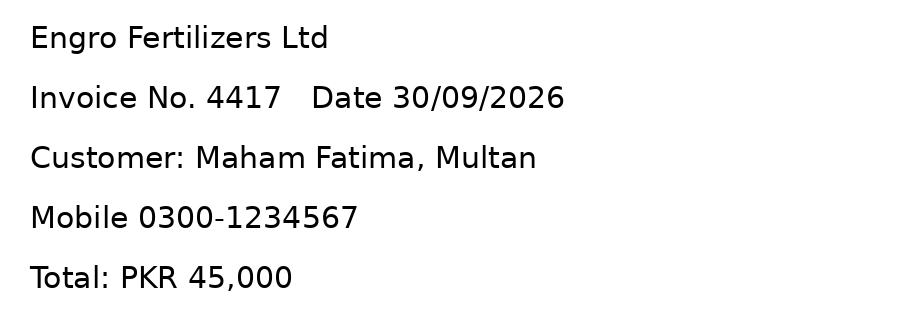

In [17]:
import os, matplotlib
from PIL import Image, ImageDraw, ImageFont

font = None
for fp in [os.path.join(matplotlib.get_data_path(), 'fonts', 'ttf', 'DejaVuSans.ttf'),
           '/usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf']:
    try:
        font = ImageFont.truetype(fp, 30)
        print('using font:', fp)
        break
    except Exception as e:
        print('font failed:', fp, '->', e)
if font is None:
    font = ImageFont.load_default(size=30)
    print('using Pillow default font')

lines = ['Engro Fertilizers Ltd', 'Invoice No. 4417   Date 30/09/2026',
         'Customer: Maham Fatima, Multan', 'Mobile 0300-1234567',
         'Total: PKR 45,000']
img = Image.new('RGB', (900, 330), 'white')
d = ImageDraw.Draw(img)
for k, line in enumerate(lines):
    d.text((30, 20 + 60 * k), line, fill='black', font=font)
img.save('invoice.png')
print('invoice.png saved')
img

In [18]:
# EasyOCR downloads its model the first time: turn Internet On in the Kaggle notebook settings.
import easyocr
reader = easyocr.Reader(['en'], gpu=False)
ocr_lines = reader.readtext('invoice.png', detail=0, paragraph=False)
ocr_text = ' '.join(ocr_lines)
print('EasyOCR output:', ocr_text)


Using CPU. Note: This module is much faster with a GPU.


EasyOCR output: Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Maham Fatima, Multan Mobile 0300-1234567 Total: PKR 45,000


In [19]:
norm = lambda s: ' '.join(s.split())
truth = norm(' '.join(lines))
raw, clean = norm(ocr_text), norm(fix_ocr(ocr_text))
print('TRUTH:', truth)
print('OCR  :', raw)
print(f'CER raw {cer(truth, raw):.3f}   after fixes {cer(truth, clean):.3f}')


TRUTH: Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Maham Fatima, Multan Mobile 0300-1234567 Total: PKR 45,000
OCR  : Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Maham Fatima, Multan Mobile 0300-1234567 Total: PKR 45,000
CER raw 0.000   after fixes 0.000


## **Write it: Part 5, Character Error Rate (CER) and OCR Repair**

**The idea.** OCR is a student copying a page by eye, and **CER is the marking scheme**: the fewest single-character edits (substitute, delete, insert) needed to turn the OCR output into the reference, divided by the **reference length**. That edit count is the **Levenshtein distance**, which I implemented from scratch in `levenshtein()`. A CER of 0.062 means about 6 wrong characters per 100.

**1. Context rules.** OCR engines confuse look-alike characters: the **letter O and the digit 0**, and the **letters l or I and the digit 1**. The rule is **not** "always replace O with 0", which would damage real words. `fix_ocr` replaces O only when **digits sit next to it** (for example inside `3O/09/2O26`), replaces l/I only **between two digits**, and turns `N0.` back into `No.`. The surrounding characters reveal what the character should be.

**2. Results on the three controlled error pairs**

| Reference | OCR output | CER before | Corrected | CER after |
|---|---|---|---|---|
| Invoice No. 4417 | Invoice N0. 4417 | **0.062** | Invoice No. 4417 | **0.000** |
| Total: PKR 12,500 | Total: PKR 12,5O0 | **0.059** | Total: PKR 12,500 | **0.000** |
| Due 30/09/2026 | Due 3O/09/2O26 | **0.143** | Due 30/09/2026 | **0.000** |

These match the lab's expected values. The first two pairs have **one** wrong character each: 1/16 = **0.062** and 1/17 = **0.059**. The date has **two** wrong characters in only 14: 2/14 = **0.143**. The same kind of mistake counts for **more in a short string**, which is why the date scores highest.

**3. CER understates the damage.** `3O/09/2O26` is only 14% wrong by character count, but my Part 4 date regex **needs digits**, so it would not match this string **at all**. An invoice number or an amount breaks the same way. One misread character can turn a field into a **total miss**, so repairing OCR output **before** extraction matters more than the small CER suggests.

**4. Real invoice test** (synthetic image, EasyOCR). I drew a five-line invoice (Engro Fertilizers, invoice 4417, date 30/09/2026, customer Maham Fatima in Multan, mobile 0300-1234567, total PKR 45,000) and ran EasyOCR on it. Whitespace was normalised first, so line breaks do not count as errors. The reference text is **123 characters** long.

| Stage | CER |
|---|---|
| Raw OCR | **0.000** |
| After `fix_ocr` | **0.000** |

The OCR text came back **identical** to the reference, so the repair rules had **nothing to fix**. They also did **no harm**, which matters: a correction step must not damage text that was already correct.

**5. Why a perfect score here does not predict real documents.** This image is the **easy case**: rendered by a computer in a clean font at 30 pixels, **black on pure white**, perfectly straight, with no noise. A real phone photo of a lab report or receipt would add:
- **uneven lighting, shadows and glare** from a crumpled or shiny page
- **rotation and perspective**, because the phone is rarely square to the paper
- **blur and compression**, which merge 0 / O and 1 / l / I exactly the way my test pairs imitate
- **stamps, handwriting and Urdu text** mixed with English, which an English-only reader handles poorly

For my own scans I **expect** a raw CER somewhere in the **0.05 to 0.20** range, with most errors in digits and punctuation. I have **not measured** this, so it is an expectation, not a result. To get a real number I would type the reference text of five reports by hand and score each with `cer()`.

**6. Risk of a wrong automatic correction.** A rule that turns O into 0 could silently change a **date, slide ID or lab value** into a different valid-looking one, and nothing would flag it. Rules like mine could also alter a real letter in text such as "Room 3O1". That is why the rules only act in **digit contexts**, why they must be tested on **negative examples** (the same discipline as Part 4), and why corrected values should still be **checked by a person**.

**Conclusion.** CER gives OCR quality a **number**, but it must be read together with **what the errors do downstream**. My cheap context rules fixed all three error patterns, but they only cover confusions I thought of **in advance**.


In [20]:
def mask_pii(text):
    """Hide personal identifiers before logging or sharing."""
    text = re.sub(PATTERNS['cnic'], '[CNIC]', text)
    text = re.sub(PATTERNS['mobile'], '[PHONE]', text)
    text = re.sub(PATTERNS['email'], '[EMAIL]', text)
    return text

print(mask_pii('CNIC 35202-1234567-1, call 0300-1234567, a@b.pk'))

CNIC [CNIC], call [PHONE], [EMAIL]


In [21]:
import os, glob, json, zipfile
import torch, torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from PIL import Image
import spacy

try:
    nlp
except NameError:
    nlp = spacy.load('en_core_web_sm')

# --- checkpoint (repack the unpacked folder if needed) ---
W6_PATH = '/kaggle/working/week6_model.pt'
if not os.path.exists(W6_PATH):
    src = '/kaggle/input/datasets/lohani13/zellowwww/week6_model'
    with zipfile.ZipFile(W6_PATH, 'w', zipfile.ZIP_STORED) as z:
        for root, dirs, files in os.walk(src):
            for f in files:
                full = os.path.join(root, f)
                z.write(full, 'week6_model/' + os.path.relpath(full, src))

ckpt = torch.load(W6_PATH, map_location='cpu', weights_only=False)
classes = ckpt['classes']
print('backbone:', ckpt['backbone'], '| img_size:', ckpt['img_size'], '| grayscale:', ckpt['grayscale'])

def rebuild(ck):
    name, k = ck['backbone'], len(ck['classes'])
    if name.startswith('resnet'):
        m = getattr(models, name)(weights=None)
        m.fc = nn.Linear(m.fc.in_features, k)
    else:
        m = models.efficientnet_b0(weights=None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, k)
    m.load_state_dict(ck['state_dict'])
    return m.eval()

img_model = rebuild(ckpt)
tf = transforms.Compose(
    ([transforms.Grayscale(3)] if ckpt['grayscale'] else []) +
    [transforms.Resize((ckpt['img_size'],) * 2), transforms.ToTensor(),
     transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def image_evidence(path):
    x = tf(Image.open(path).convert('L' if ckpt['grayscale'] else 'RGB'))
    with torch.no_grad():
        p = F.softmax(img_model(x.unsqueeze(0)), 1)[0].numpy()
    return {c: round(float(v), 3) for c, v in zip(classes, p)}

# warning terms for a malaria / fever-illness note
URGENT = ['fever', 'chills', 'rigors', 'vomiting', 'headache',
          'confusion', 'jaundice', 'breath', 'seizure']

def text_evidence(note):
    doc = nlp(note)
    return {'entities': [(e.text, e.label_) for e in doc.ents],
            'fields': extract_fields(note),
            'urgent_terms': [k for k in URGENT if k in note.lower()]}

# --- one test image of the class we must not miss ---
POSITIVE = 'Parasitized'
base = '/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria'
EXAMPLE_IMAGE = next(glob.iglob(f'{base}/**/{POSITIVE}/*.png', recursive=True))
print('classes:', classes)
print('test image:', EXAMPLE_IMAGE)
print(image_evidence(EXAMPLE_IMAGE))

# a second image from the other class, for the disagreement case later
OTHER_IMAGE = next(glob.iglob(f'{base}/**/Uninfected/*.png', recursive=True))
print('other image:', OTHER_IMAGE)
print(image_evidence(OTHER_IMAGE))

backbone: resnet18 | img_size: 224 | grayscale: False
classes: ['Parasitized', 'Uninfected']
test image: /kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/Parasitized/C100P61ThinF_IMG_20150918_144104_cell_162.png
{'Parasitized': 1.0, 'Uninfected': 0.0}
other image: /kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/Uninfected/C100P61ThinF_IMG_20150918_144104_cell_128.png
{'Parasitized': 0.003, 'Uninfected': 0.997}


In [22]:
def case_record(image_path, note, positive, threshold=0.5):
    safe_note = mask_pii(note)                  # mask BEFORE any extraction
    img_ev, txt_ev = image_evidence(image_path), text_evidence(safe_note)
    p = img_ev[positive]
    reasons = []
    if p >= threshold:
        reasons.append(f'image model: P({positive}) = {p:.2f}')
    if txt_ev['urgent_terms']:
        reasons.append('note mentions: ' + ', '.join(txt_ev['urgent_terms']))
    return {'image': image_path.split('/')[-1],
            'image_probabilities': img_ev,
            'note_masked': safe_note,
            'text_evidence': txt_ev,
            'decision': 'REFER' if reasons else 'ROUTINE',
            'reasons': reasons,
            'disclaimer': 'Decision support only; a qualified human decides.'}

note = ('Patient Alisha Noor, aged 24, has fever with chills for 4 days after '
        'travel. Blood smear taken at PIMS Islamabad on 12/10/2026. '
        'Contact 0300-1234567, CNIC 35202-1234567-1.')

rec = case_record(EXAMPLE_IMAGE, note, positive=POSITIVE)
out = json.dumps(rec, indent=2, ensure_ascii=False)
print(out)
print('\nPhone leaked?', '1234567' in out, '| CNIC leaked?', '35202' in out)

# disagreement case: healthy-looking cell image, but a worrying note
rec2 = case_record(OTHER_IMAGE, note, positive=POSITIVE)
print('\nDisagreement case ->', rec2['decision'], rec2['reasons'])

{
  "image": "C100P61ThinF_IMG_20150918_144104_cell_162.png",
  "image_probabilities": {
    "Parasitized": 1.0,
    "Uninfected": 0.0
  },
  "note_masked": "Patient Alisha Noor, aged 24, has fever with chills for 4 days after travel. Blood smear taken at PIMS Islamabad on 12/10/2026. Contact [PHONE], CNIC [CNIC].",
  "text_evidence": {
    "entities": [
      [
        "Alisha Noor",
        "PERSON"
      ],
      [
        "24",
        "DATE"
      ],
      [
        "4 days",
        "DATE"
      ],
      [
        "PIMS",
        "ORG"
      ],
      [
        "12/10/2026",
        "DATE"
      ],
      [
        "CNIC",
        "ORG"
      ],
      [
        "CNIC",
        "ORG"
      ]
    ],
    "fields": {
      "date": [
        "12/10/2026"
      ]
    },
    "urgent_terms": [
      "fever",
      "chills"
    ]
  },
  "decision": "REFER",
  "reasons": [
    "image model: P(Parasitized) = 1.00",
    "note mentions: fever, chills"
  ],
  "disclaimer": "Decision support only

## **Write it: Part 6, Image + Text Case Record (with Privacy)**

**The idea.** Two assistants each give evidence, and **neither decides**. One only looks at the blood-smear image; the other only reads the clinical note. The **record** is the folder that holds both reports side by side, so a human can see **why** a case was sent forward.

**1. My setup**
- **Image model (Week 6):** **ResNet-18** transfer learning, **224 x 224 RGB** input, two classes **`Parasitized`** and **`Uninfected`**. `Parasitized` is the class I **must not miss**.
- **Text side:** spaCy entities, my regex fields, and a warning list I wrote for fever illness: fever, chills, rigors, vomiting, headache, confusion, jaundice, breath, seizure.
- **Test note:** *"Patient Alisha Noor, aged 24, has fever with chills for 4 days after travel. Blood smear taken at PIMS Islamabad on 12/10/2026. Contact 0300-1234567, CNIC 35202-1234567-1."* I included a phone number and a CNIC **on purpose**, so the masking has something real to hide.

**2. The record I produced**

| Part | Result |
|---|---|
| **Image evidence** | P(Parasitized) = **1.000**, P(Uninfected) = 0.000 |
| **Masked note** | "...Contact **[PHONE]**, CNIC **[CNIC]**." |
| **Entities found** | Alisha Noor (PERSON), 24 (DATE), 4 days (DATE), PIMS Islamabad (ORG), 12/10/2026 (DATE), CNIC (ORG) x2 |
| **Fields found** | date: 12/10/2026 |
| **Urgent terms** | **fever, chills** |
| **Decision** | **REFER** |
| **Reasons** | "image model: P(Parasitized) = 1.00" and "note mentions: fever, chills" |

**3. Why each reason was produced.** The **image reason** appears only if P(Parasitized) is at least the **0.50 threshold**; here it is **1.00**, so it appeared. The **note reason** appears whenever the note contains a term from my warning list; **fever** and **chills** are both in it. **Either source alone is enough** to refer. Both reasons are specific and checkable against the evidence in the same record. One caution: **1.000 is a softmax output, not a measured accuracy.** Neural networks are often **overconfident**, so I read it as "the model is very sure", not "there is a 100% chance".

**4. A wrong entity, and whether it matters.** spaCy tagged **"24" as DATE**, but it is the patient's **age**. Here it is **harmless**, because my decision rule reads **only the image probability and the urgent terms**, never the entity list. It would become **harmful** if a later step used age for triage or dosing, because a pipeline reading DATE entities would treat 24 as a date and lose the age. Other issues: the word **"CNIC" was tagged ORG twice** (the label and the `[CNIC]` placeholder, harmless leftovers of masking), and **"PIMS Islamabad" was merged into one ORG** where my gold standard splits it into PIMS (ORG) and Islamabad (GPE). So roughly **3 to 4 of the 7 entities are doubtful**, which fits the held-out accuracy from Part 3 and is why entities are **supporting evidence only**.

**5. Privacy check.** I searched the final JSON for the digits of the phone number (`1234567`) and the CNIC (`35202`). Both checks returned **False**. The `fields` block contains only `date`, with **no `mobile` or `cnic` key at all**, which is the proof that masking happened **first**. If extraction had run on the original note, my own mobile regex would have returned the number and put it back into `text_evidence`.

**6. Masking order.** `case_record` calls `mask_pii` **before** any extraction, so the entity and field steps only ever see the **masked** note. There is a second reason to mask first: in Part 3 spaCy labelled a phone number as a **DATE**, so unmasked identifiers would also **pollute the entity list** with wrong labels.

**7. A disagreement case.** I kept the same worrying note but swapped in a **healthy cell image**. The model gave **P(Uninfected) = 0.996** (P(Parasitized) = 0.004), and the system still returned **REFER**, with the **only reason being the note** (*fever, chills*). That is the **right direction to fail**: missing a malaria case is far more costly than sending one extra patient for a repeat test, so **any single source of evidence is enough to refer**.

**8. Why disagreement should go to a human, not be overwritten.** Each source can be wrong in a different way. A patient's smear contains **thousands of cells** and my model looks at **one cropped cell**, so one clean cell **cannot rule out infection**. A note can also be **outdated** or describe a different illness. Letting one source overwrite the other would **hide the conflict**. I would improve the record in two ways: add an explicit field such as `"conflict": "image negative, note urgent"` (right now the record lists only the note as the reason and does not mention that the image said Uninfected), and suggest a **repeat smear or rapid test**. The final decision stays with the **clinician**, as the disclaimer in the record says.

**9. Domain and population limits.** The Week 6 model was trained on **single segmented cell images** from one public dataset. Different **stains, microscopes, labs and patient populations** can change the pictures, so it needs **validation on local Pakistani lab images** before real use. The output is **decision support, not a diagnosis**.

**Conclusion.** The record works because it is **transparent**, not because it is smart: every reason can be traced, identifiers **never reach the logs**, and a disagreement leads to a **referral**, not silence. What it still lacks is **calibrated confidence** and an explicit **conflict flag**.


## **Written answers: Check Your Understanding**

**1. A word appears in 9 of 1,000 documents. Compute its smooth IDF.**

Smooth IDF is `idf = ln[(1 + N) / (1 + df)] + 1`, with **N = 1000** and **df = 9**:

idf = ln(1001 / 10) + 1 = ln(100.1) + 1 = 4.606 + 1 = **5.606**

**Meaning:** this is a **rare** word, so it gets a **high** weight. For comparison, a word in all 1,000 documents gets ln(1) + 1 = **1.000**, the minimum. The "+1" keeps even the most common word at a weight above zero.

**2. Why can lowercasing hurt a spam classifier?**

Lowercasing is a common default, but it **destroys information**. Spam often uses **capitalisation and mixed-case tricks** on purpose: `FREE`, `CLAIM`, `W1N a FR33 pr1ze`. If every message is lowercased, `FREE` and `free` become the same token, and the model **loses a spam signal** that a normal friendly message rarely has. It can also change meaning for names and acronyms. Whether keeping case helps must be **tested on held-out data**: train one model with lowercasing and one without, and compare **macro-F1** (and spam recall) on the same test split.

**3. Gold has 10 entities; the model predicts 8, of which 6 are exactly right. Compute precision, recall and F1.**

- **TP = 6**, **FP = 8 - 6 = 2**, **FN = 10 - 6 = 4**
- **Precision** = TP / predicted = 6 / 8 = **0.75**
- **Recall** = TP / gold = 6 / 10 = **0.60**
- **F1** = 2 x P x R / (P + R) = 2 x 0.75 x 0.60 / (0.75 + 0.60) = 0.90 / 1.35 = **0.667**

**Meaning:** when the model speaks it is right 75% of the time, but it finds only 60% of the real entities. "Exactly right" means **text and label both match**, so a correct entity with a wrong boundary counts as one FP **and** one FN.

**4. Reference `PKR 4,500`, OCR output `PKR 4,5OO`. Compute CER.**

- The reference `PKR 4,500` has **9 characters** (P, K, R, space, 4, comma, 5, 0, 0).
- The OCR output differs in the **last two characters**: the digits `00` were read as the letters `OO`. That is **2 substitutions**, so the edit distance is **2**.
- **CER** = edit distance / reference length = 2 / 9 = **0.222**

**Meaning:** about 22% of the characters are wrong. The context rule from Part 5 (an O between or after digits becomes 0) would repair this string to CER **0.000**.

**5. Image model says 0.30, text model says 0.80, and w = 0.5. What is the fused probability?**

P(fused) = w x P(image) + (1 - w) x P(text) = 0.5 x 0.30 + 0.5 x 0.80 = 0.15 + 0.40 = **0.55**

**Meaning and caution:** with equal weights the answer is the **simple average**, and it sits just above 0.5, so the two sources **partly disagree**. This is a plain weighted average, **not a calibrated probability**. It is only trustworthy if both models are calibrated and **w** was chosen on validation data. In my notebook I did **not** fuse numbers at all: I kept both sources visible, and **either one** can trigger a human review, which is safer for a medical task.

**6. Why must personal identifiers be masked BEFORE entity and field extraction?**

If extraction runs on the **original** note, names, phone numbers and CNICs are **copied into the structured output** (`entities`, `fields`) even when the displayed note is masked. The identifiers then leak into logs and JSON through the side door. Masking **first** means every later step sees only `[PHONE]` and `[CNIC]`, so they **cannot** be copied. In my own record the `fields` block contained only `date`, and the digit search for `1234567` and `35202` returned **False**. There is a second benefit: unmasked identifiers also **pollute the entity list** with wrong labels, as in Part 3 where spaCy labelled a phone number as a **DATE**.
